# Modeling results

In [16]:
# Automatic module reloading
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Add project root
PROJ_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJ_ROOT))

# Notebooks imports
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 0. Load results

In [17]:
### LINEAR
# Pooled prediction csvs
linear_random = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_linear_random/predictions.csv")
linear_grouped = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_linear_grouped/predictions.csv")
linear_loso = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_linear_loso/predictions.csv")
linear_lomo = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_linear_lomo/predictions.csv")
# Metrics jsons
linear_random_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_linear_random/metrics.json"))
linear_grouped_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_linear_grouped/metrics.json"))
linear_loso_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_linear_loso/metrics.json"))
linear_lomo_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_linear_lomo/metrics.json"))


### MLP
# Pooled prediction csvs
mlp_random = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_mlp_random/predictions.csv")
mlp_grouped = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_mlp_grouped/predictions.csv")
mlp_loso = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_mlp_loso/predictions.csv")
mlp_lomo = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_mlp_lomo/predictions.csv")
# Metrics jsons
mlp_random_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_mlp_random/metrics.json"))
mlp_grouped_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_mlp_grouped/metrics.json"))
mlp_loso_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_mlp_loso/metrics.json"))
mlp_lomo_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_mlp_lomo/metrics.json"))


### RANDOM FOREST
# Pooled prediction csvs
rf_random = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_rf_random/predictions.csv")
rf_grouped = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_rf_grouped/predictions.csv")
rf_loso = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_rf_loso/predictions.csv")
rf_lomo = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_rf_lomo/predictions.csv")
# Metrics jsons
rf_random_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_rf_random/metrics.json"))
rf_grouped_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_rf_grouped/metrics.json"))
rf_loso_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_rf_loso/metrics.json"))
rf_lomo_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_rf_lomo/metrics.json"))


### XGB
# Pooled prediction csvs
xgb_random = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_random/predictions.csv")
xgb_grouped = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_grouped/predictions.csv")
xgb_loso = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_loso/predictions.csv")
xgb_lomo = pd.read_csv(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_lomo/predictions.csv")

# Metrics jsons
xgb_random_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_random/metrics.json"))
xgb_grouped_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_grouped/metrics.json"))
xgb_loso_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_loso/metrics.json"))
xgb_lomo_metrics = json.load(open(PROJ_ROOT / "reports/maxod_aero_anaero_xgb_lomo/metrics.json"))


## Quick EDA on training dataset

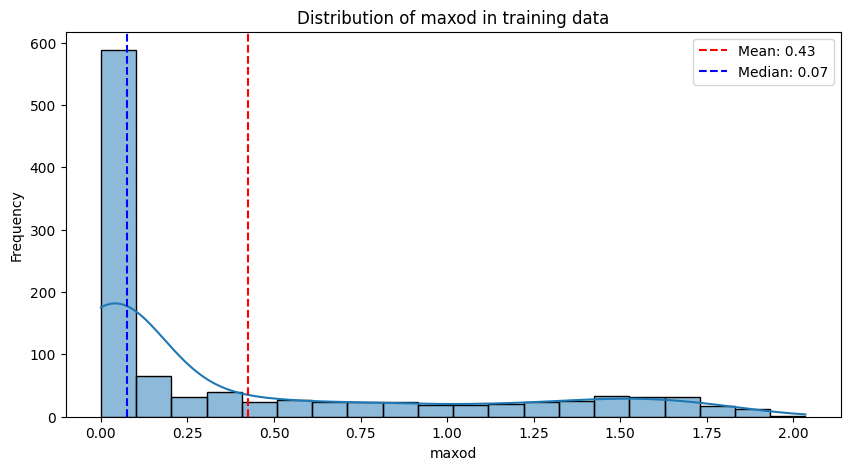

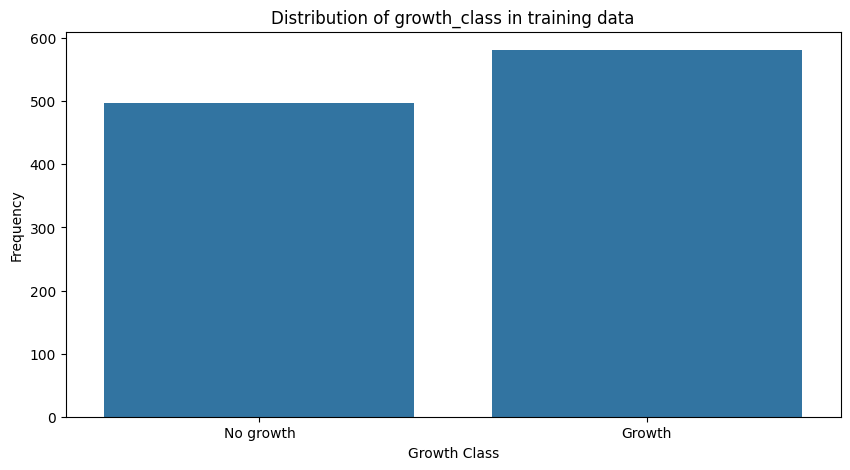

In [18]:
aero_an10aero_dataset = pd.read_csv(PROJ_ROOT / "data/interim/aero_anaero_modeling_dataset.csv")
mean_maxod = aero_anaero_dataset['max_od'].mean()
median_maxod = aero_anaero_dataset['max_od'].median()

# Plot distribution of training data
# MaxOD
fig = plt.figure(figsize=(10, 5))
sns.histplot(aero_anaero_dataset['max_od'], bins=20, kde=True)
plt.title('Distribution of maxod in training data')
# Add legend with metrics
plt.axvline(mean_maxod, color='red', linestyle='--', label=f'Mean: {mean_maxod:.2f}')
plt.axvline(median_maxod, color='blue', linestyle='--', label=f'Median: {median_maxod:.2f}')
plt.xlabel('maxod')
plt.ylabel('Frequency')
plt.legend()
plt.show()


# growth_class
fig = plt.figure(figsize=(10, 5))
sns.countplot(data=aero_anaero_dataset, x='growth_class')
plt.title('Distribution of growth_class in training data')
plt.xlabel('Growth Class')
plt.ylabel('Frequency')
plt.xticks(ticks=[0, 1], labels=['No growth', 'Growth']) # Adjust labels as needed
plt.show()

### Metrics to use

#### MaxOD - regression
- Right tailed data where most of the datapoints are around 0-0.1 
- Cannot use metrics that assume normal distribution (eg $R^2$)
- Metrics of choice
   - RMSE: quadratic penalty 
      - will be dominated by the errors produced by large MaxOD, because most datpoints are low MaxOD
   - MAE: linear penalty
      - this makes it more robust to outliers 
   - Both RMSE and MAE are the same units as the target value (OD units)
- Gap RMSE - MAE
   - if RMSE is much bigger than MAE, then outliers dominate the error
   - if RMSE is similar to MAE, then the erros are evenly distributed (eg predicting high and low growth)

#### Growth class - classification

## 1. Predictions scatter

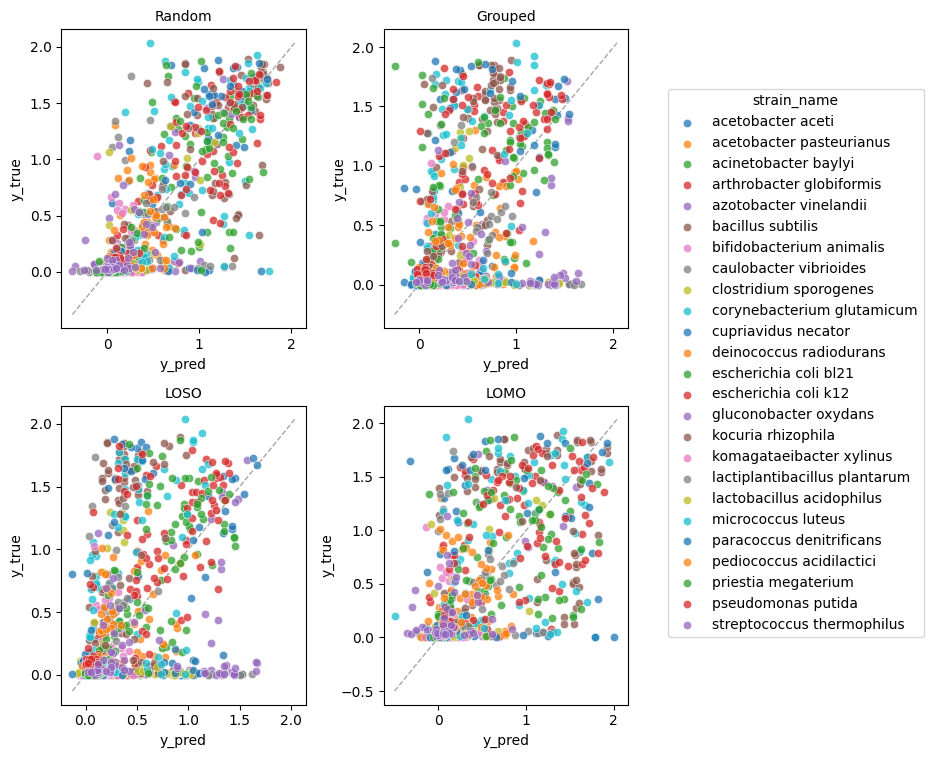

In [19]:
from src.modeling.plots import plot_scatter_predictions

fig = plot_scatter_predictions([xgb_random, xgb_grouped, xgb_loso, xgb_lomo], 
                               titles=["Random", "Grouped", "LOSO", "LOMO"], 
                               color_by="strain_name")

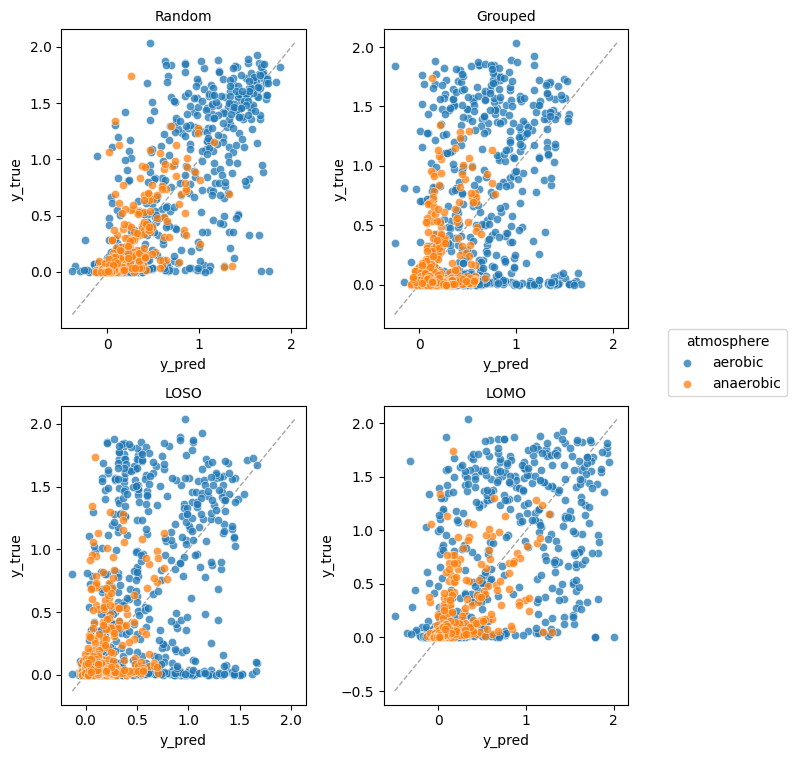

In [20]:
from src.modeling.plots import plot_scatter_predictions

fig = plot_scatter_predictions([xgb_random, xgb_grouped, xgb_loso, xgb_lomo], 
                               titles=["Random", "Grouped", "LOSO", "LOMO"], 
                               color_by="atmosphere")

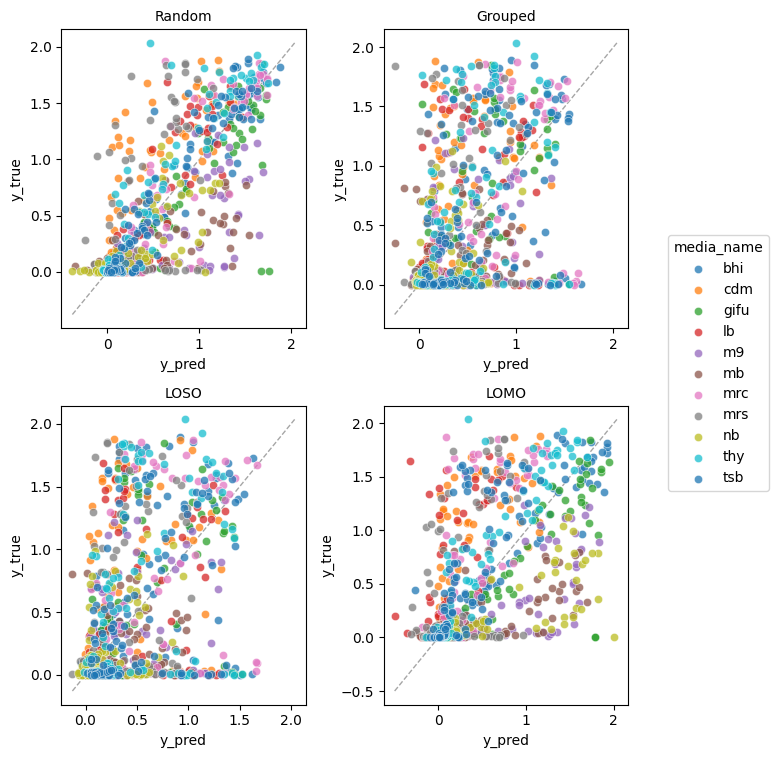

In [21]:
from src.modeling.plots import plot_scatter_predictions

fig = plot_scatter_predictions([xgb_random, xgb_grouped, xgb_loso, xgb_lomo], 
                               titles=["Random", "Grouped", "LOSO", "LOMO"], 
                               color_by="media_name")

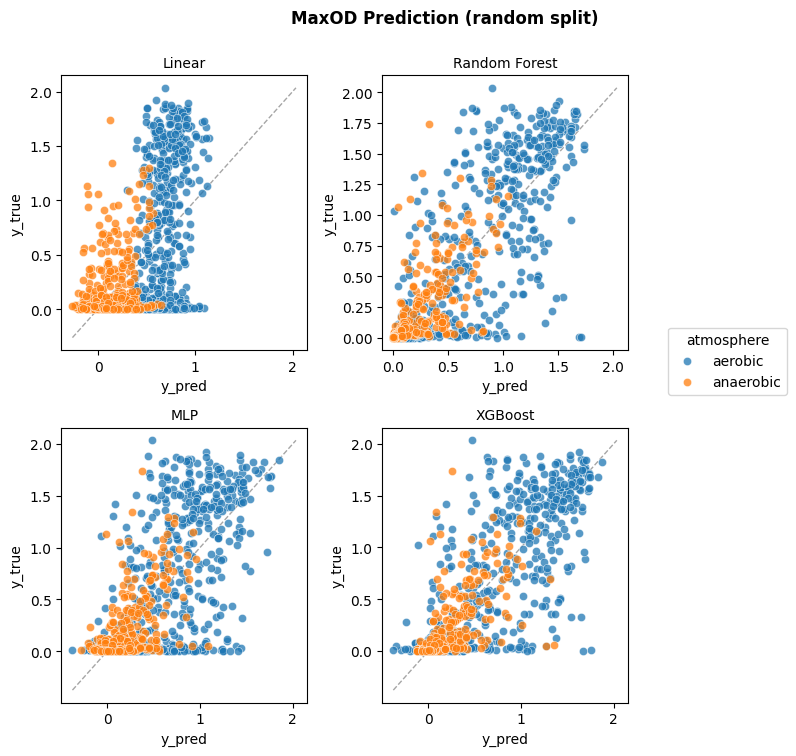

In [22]:
from src.modeling.plots import plot_scatter_predictions

fig = plot_scatter_predictions([linear_random, rf_random, mlp_random, xgb_random], 
                               titles=["Linear", "Random Forest", "MLP", "XGBoost"], 
                               color_by="atmosphere",
                               fig_title="MaxOD Prediction (random split)")

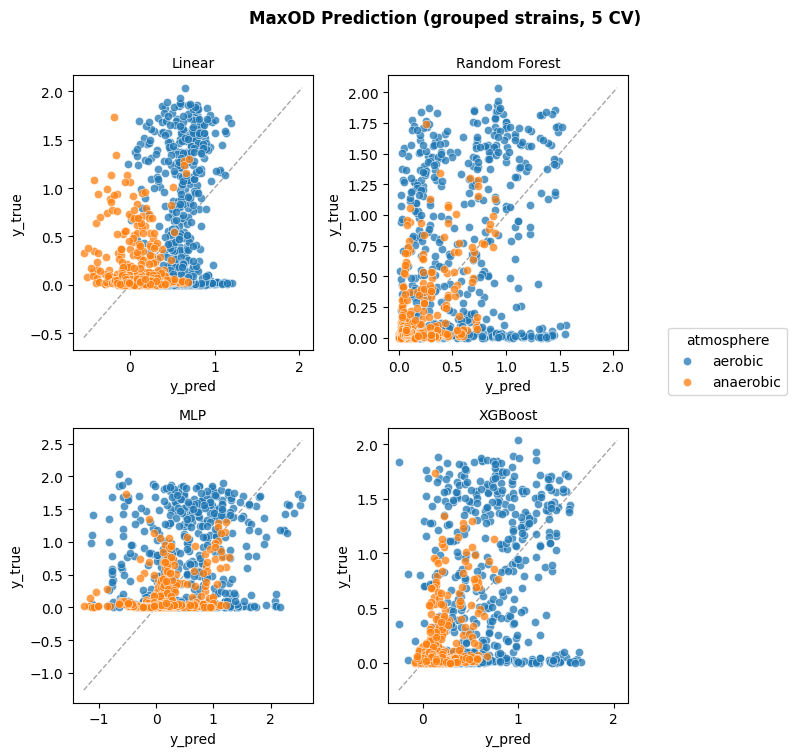

In [23]:
from src.modeling.plots import plot_scatter_predictions

fig = plot_scatter_predictions([linear_grouped, rf_grouped, mlp_grouped, xgb_grouped], 
                               titles=["Linear", "Random Forest", "MLP", "XGBoost"], 
                               color_by="atmosphere",
                               fig_title="MaxOD Prediction (grouped strains, 5 CV)")

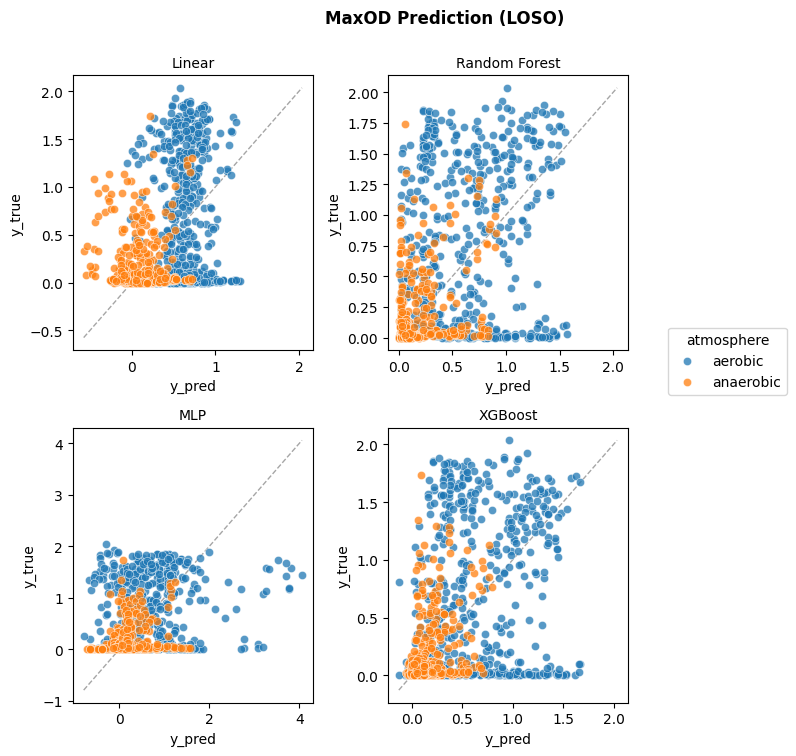

In [24]:
from src.modeling.plots import plot_scatter_predictions

fig = plot_scatter_predictions([linear_loso, rf_loso, mlp_loso, xgb_loso], 
                               titles=["Linear", "Random Forest", "MLP", "XGBoost"], 
                               color_by="atmosphere",
                               fig_title="MaxOD Prediction (LOSO)")

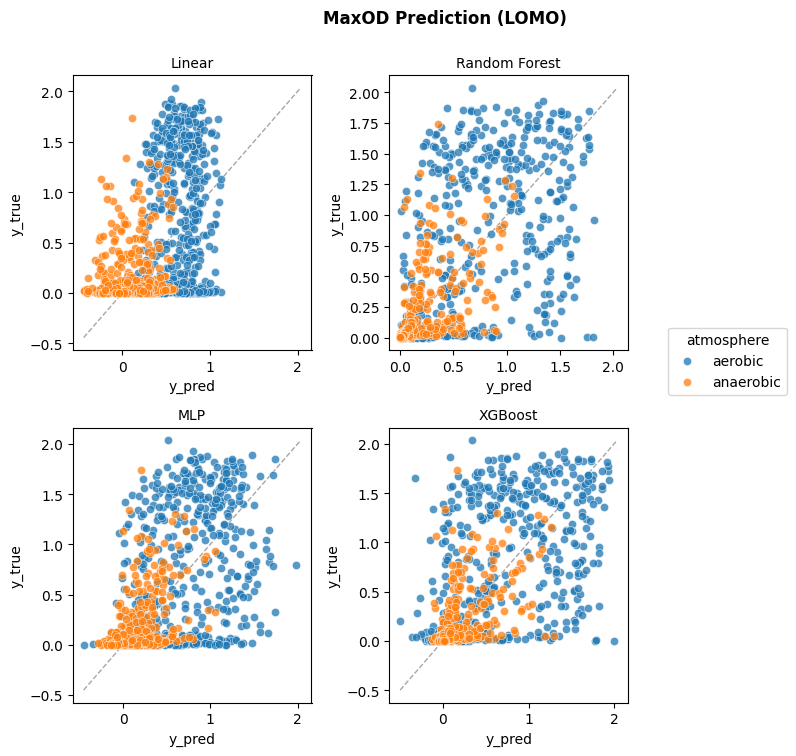

In [25]:
from src.modeling.plots import plot_scatter_predictions

fig = plot_scatter_predictions([linear_lomo, rf_lomo, mlp_lomo, xgb_lomo], 
                               titles=["Linear", "Random Forest", "MLP", "XGBoost"], 
                               color_by="atmosphere",
                               fig_title="MaxOD Prediction (LOMO)")

## 2.1. Metrics across splits

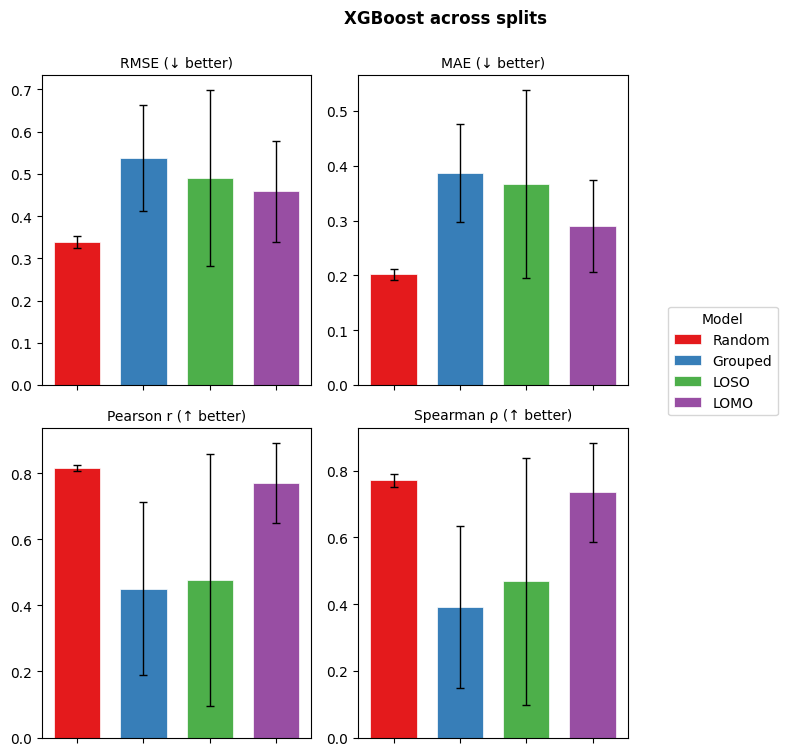

In [26]:
from src.modeling.plots import plot_metrics_comparison

fig = plot_metrics_comparison([xgb_random_metrics, xgb_grouped_metrics, xgb_loso_metrics, xgb_lomo_metrics], 
                              metrics=["rmse", "mae", "pearson_r", "spearman_r"],
                              metric_titles=["RMSE (↓ better)", "MAE (↓ better)", "Pearson r (↑ better)", "Spearman ρ (↑ better)"],
                              json_titles=["Random", "Grouped", "LOSO", "LOMO"],
                              fig_title="XGBoost across splits")


## 2.2. Metrics across models

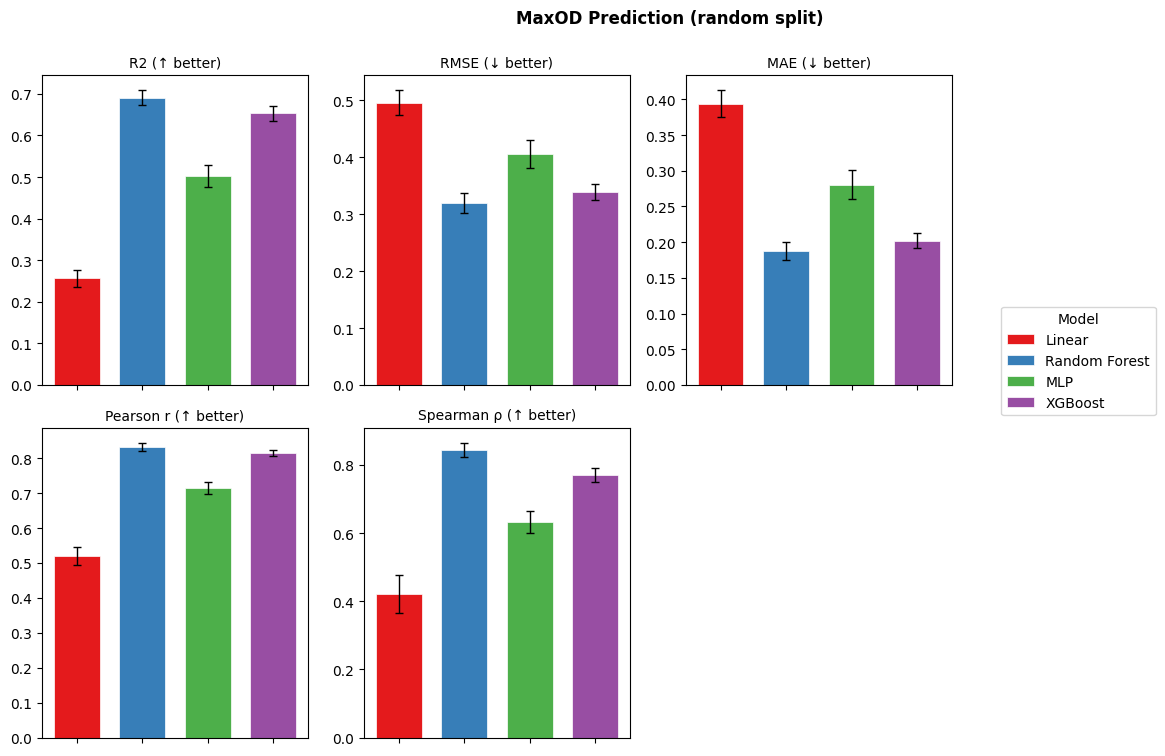

In [27]:
from src.modeling.plots import plot_metrics_comparison

# Random split
fig = plot_metrics_comparison([linear_random_metrics, rf_random_metrics, mlp_random_metrics, xgb_random_metrics], 
                              metrics=["r2", "rmse", "mae", "pearson_r", "spearman_r"],
                              metric_titles=["R2 (↑ better)", "RMSE (↓ better)", "MAE (↓ better)", "Pearson r (↑ better)", "Spearman ρ (↑ better)"],
                              json_titles=["Linear", "Random Forest", "MLP", "XGBoost"],
                              fig_title="MaxOD Prediction (random split)",
                              col_wrap=3)

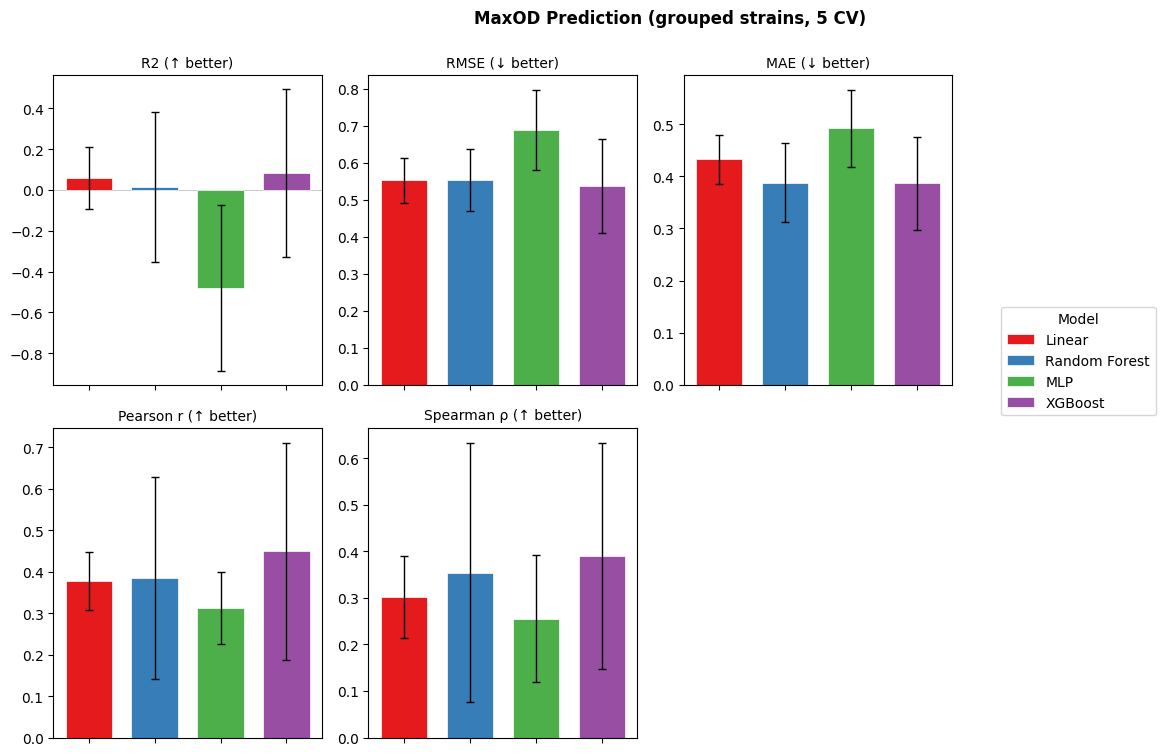

In [28]:
from src.modeling.plots import plot_metrics_comparison

# Grouped split
fig = plot_metrics_comparison([linear_grouped_metrics, rf_grouped_metrics, mlp_grouped_metrics, xgb_grouped_metrics], 
                              metrics=["r2", "rmse", "mae", "pearson_r", "spearman_r"],
                              metric_titles=["R2 (↑ better)", "RMSE (↓ better)", "MAE (↓ better)", "Pearson r (↑ better)", "Spearman ρ (↑ better)"],
                              json_titles=["Linear", "Random Forest", "MLP", "XGBoost"],
                              fig_title="MaxOD Prediction (grouped strains, 5 CV)",
                              col_wrap=3)

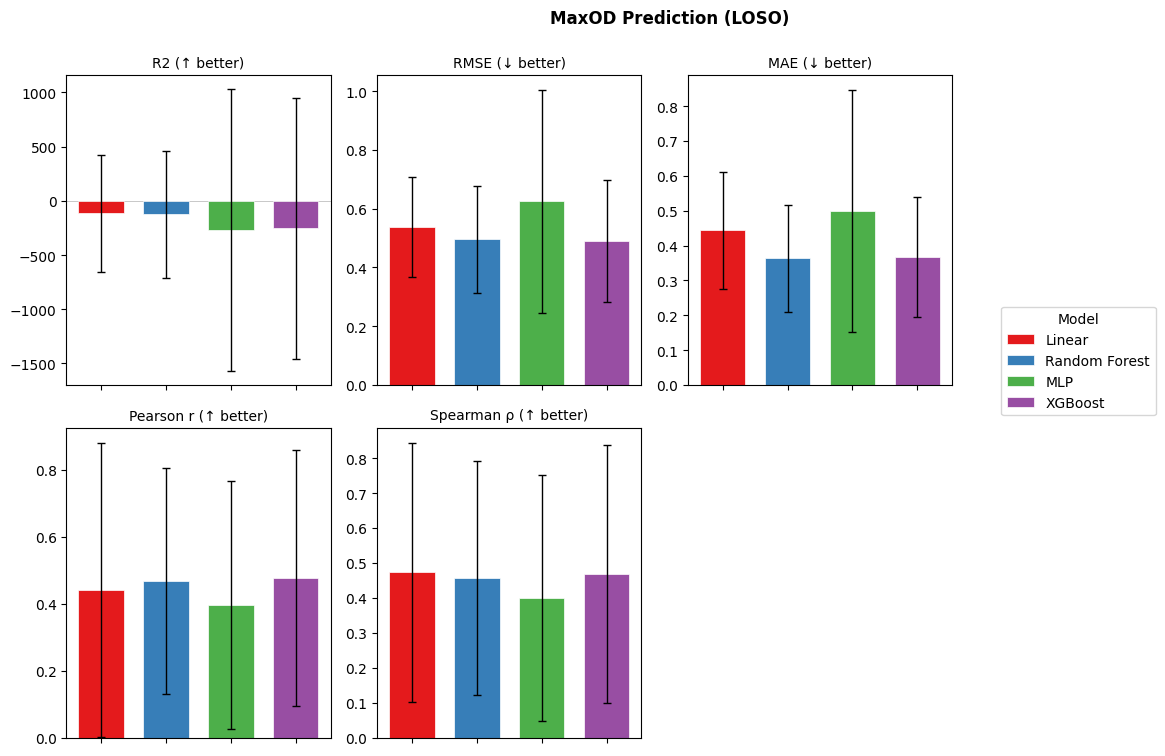

In [29]:
# LOSO split
fig = plot_metrics_comparison([linear_loso_metrics, rf_loso_metrics, mlp_loso_metrics, xgb_loso_metrics], 
                              metrics=["r2", "rmse", "mae", "pearson_r", "spearman_r"],
                              metric_titles=["R2 (↑ better)", "RMSE (↓ better)", "MAE (↓ better)", "Pearson r (↑ better)", "Spearman ρ (↑ better)"],
                              json_titles=["Linear", "Random Forest", "MLP", "XGBoost"],
                              fig_title="MaxOD Prediction (LOSO)",
                              col_wrap=3)

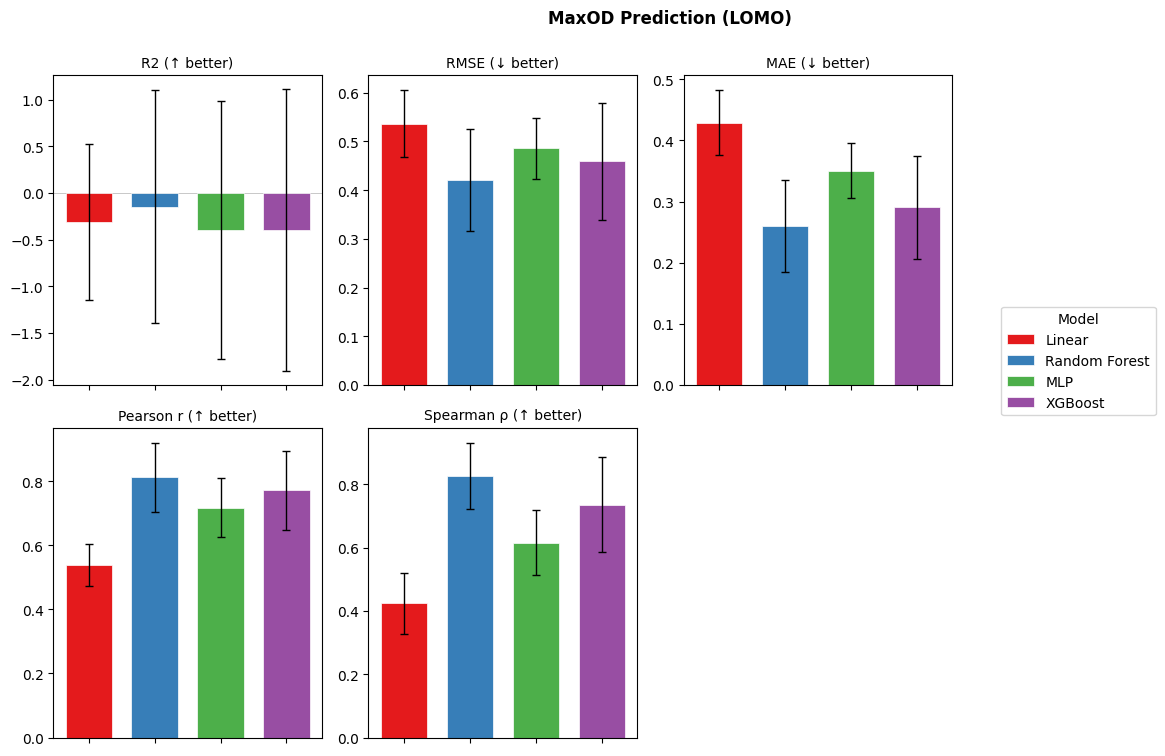

In [30]:
# LOMO split
fig = plot_metrics_comparison([linear_lomo_metrics, rf_lomo_metrics, mlp_lomo_metrics, xgb_lomo_metrics], 
                              metrics=["r2", "rmse", "mae", "pearson_r", "spearman_r"],
                              metric_titles=["R2 (↑ better)", "RMSE (↓ better)", "MAE (↓ better)", "Pearson r (↑ better)", "Spearman ρ (↑ better)"],
                              json_titles=["Linear", "Random Forest", "MLP", "XGBoost"],
                              fig_title="MaxOD Prediction (LOMO)",
                              col_wrap=3)